# Task 1 · EDA on Retail Sales Data

This notebook explores orders from the AdventureWorks sample retailer, a bicycle business whose sales, customers, and products are stored as three related tables. The orders run from 29 December 2010 to 28 January 2014.

The question is where the money actually comes from: which months, which customers, and which products.


## 1. Setup


In [1]:
from pathlib import Path

%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 2)
pd.set_option("display.max_rows", 20)

DATA = Path("data")
AGE_BINS = [0, 24, 34, 44, 54, 64, 120]
AGE_LABELS = ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]


## 2. Load and inspect

Each row in the sales table is one product line on an order. Customer age is not stored directly. It is calculated from the birth date and the order date. `create_date` is checked before it is used, because a customer-created date should fall before that customer's orders.


In [2]:
customers = pd.read_csv(DATA / "dim_customers.csv", parse_dates=["birthdate", "create_date"])
products = pd.read_csv(DATA / "dim_products.csv")
sales = pd.read_csv(DATA / "fact_sales.csv", parse_dates=["order_date", "shipping_date", "due_date"])

print("customers", customers.shape)
print("products", products.shape)
print("sales", sales.shape)
print("order dates", sales["order_date"].min(), "to", sales["order_date"].max())
print("create_date", customers["create_date"].min().date(), "to", customers["create_date"].max().date())


customers (18484, 10)
products (295, 11)
sales (60398, 9)
order dates 2010-12-29 00:00:00 to 2014-01-28 00:00:00
create_date 2025-10-06 to 2026-01-27


In [3]:
pd.DataFrame({
    "customers": customers.dtypes.astype(str),
}).join(pd.DataFrame({"products": products.dtypes.astype(str)}), how="outer").join(
    pd.DataFrame({"sales": sales.dtypes.astype(str)}), how="outer"
)


,customers,products,sales
birthdate,datetime64[us],NaN,NaN
category,NaN,str,NaN
category_id,NaN,str,NaN
cost,NaN,int64,NaN
country,str,NaN,NaN
...,...,...,...
quantity,NaN,NaN,int64
sales_amount,NaN,NaN,int64
shipping_date,NaN,NaN,datetime64[us]
start_date,NaN,str,NaN


In [4]:
nulls = pd.DataFrame({
    "customers": customers.isna().sum(),
    "products": products.isna().sum(),
    "sales": sales.isna().sum(),
}).fillna(0).astype(int)
nulls.loc[nulls.sum(axis=1) > 0]


,customers,products,sales
birthdate,17,0,0
category,0,7,0
country,337,0,0
gender,15,0,0
maintenance,0,7,0
order_date,0,0,19
product_line,0,17,0
subcategory,0,7,0


The sales table has 60,398 lines, the customer table 18,484 people, and the product table 295 items.

`create_date` runs from 6 October 2025 to 27 January 2026. Every order is from 2014 or earlier, so this column is a warehouse load timestamp, not the day the customer signed up. It is left out of the analysis.

Nineteen sales lines have no order date. Fifteen customers have no gender, seventeen have no birth date, and 337 have no country. Those rows stay in the revenue totals and are dropped only from the chart that needs the missing field. The product catalogue contains components, but none of the sales lines are components: the orders are bikes, accessories, and clothing.


## 3. Descriptive statistics


In [5]:
analysis = sales.merge(customers, on="customer_key", how="left").merge(products, on="product_key", how="left")
analysis["age"] = ((analysis["order_date"] - analysis["birthdate"]).dt.days / 365.25).round(0)

numbers = analysis[["age", "quantity", "price", "cost", "sales_amount"]]
summary = pd.DataFrame({
    "mean": numbers.mean(),
    "median": numbers.median(),
    "mode": numbers.mode().iloc[0],
    "std": numbers.std(),
})
summary


,mean,median,mode,std
age,44.04,42.0,38.0,11.36
quantity,1.00,1.0,1.0,0.04
price,486.04,30.0,5.0,928.45
cost,292.56,11.0,2.0,563.25
sales_amount,486.05,30.0,5.0,928.45


Price and sales amount tell the same story. The mean line is about 486, the median is 30, and the most common value is 5. A small number of expensive bikes pull the mean far above what a typical line costs.

Product cost is skewed the same way. The mean cost on a line is about 293, the median is 11, and the most common cost is 2.

Quantity does not vary. The mean, median, and mode are all 1, and the standard deviation is 0.04. Almost every line is a single unit, so the sales amount on a line is effectively the price.

Age on the order lines has a mean of 44 and a median of 42. Identifier columns such as customer and product keys are excluded here because an average key has no business meaning.


## 4. Monthly and quarterly sales


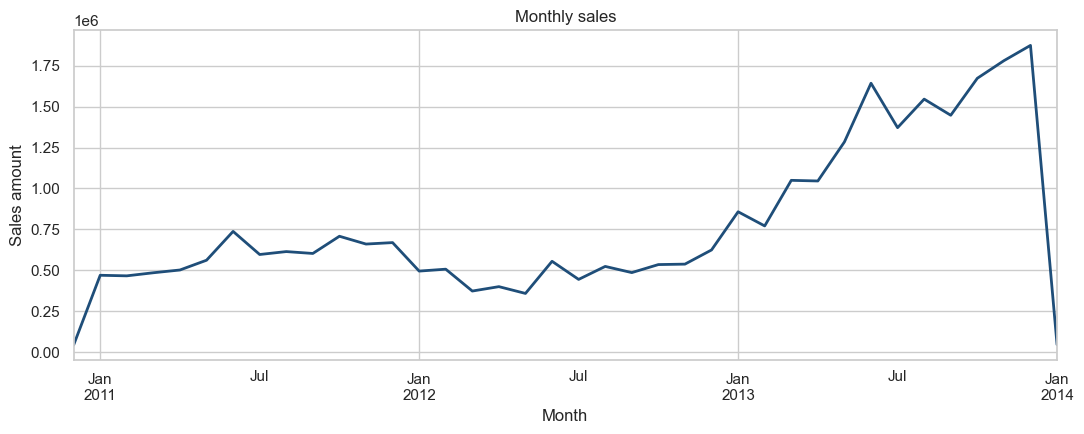

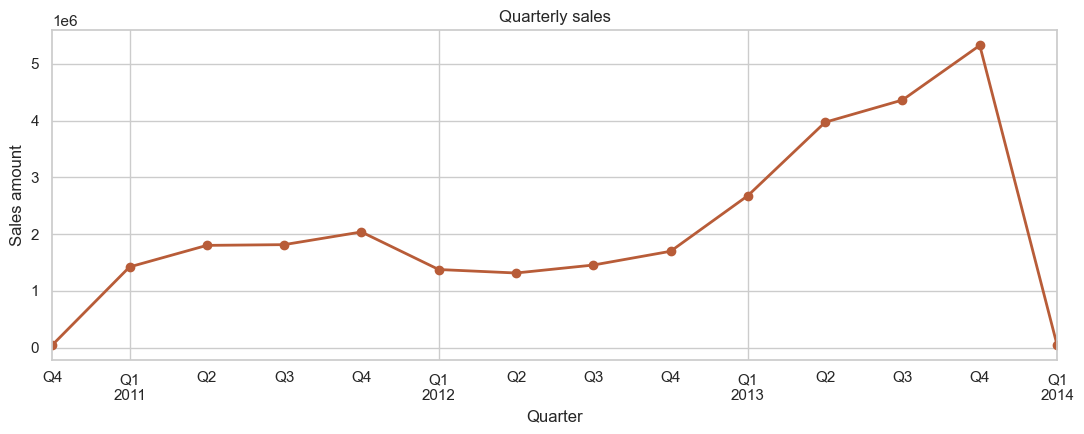

order_date
2010-01-01       43419
2011-01-01     7075088
2012-01-01     5842231
2013-01-01    16344878
2014-01-01       45642
Freq: YS-JAN, Name: sales_amount, dtype: int64

In [6]:
dated = analysis.dropna(subset=["order_date"]).set_index("order_date")
monthly = dated["sales_amount"].resample("MS").sum()
quarterly = dated["sales_amount"].resample("QS").sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
monthly.plot(ax=ax, color="#1f4e79", linewidth=2)
ax.set_title("Monthly sales")
ax.set_xlabel("Month")
ax.set_ylabel("Sales amount")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5))
quarterly.plot(ax=ax, color="#b85c38", linewidth=2, marker="o")
ax.set_title("Quarterly sales")
ax.set_xlabel("Quarter")
ax.set_ylabel("Sales amount")
fig.tight_layout()
plt.show()

yearly = dated["sales_amount"].resample("YS").sum()
yearly


December 2010 and January 2014 are partial months, so the low points at both ends of the line are incomplete periods, not a collapse in demand.

The full years are comparable. Sales were 7.08 million in 2011, 5.84 million in 2012, and 16.34 million in 2013. The business dipped in 2012 and then nearly tripled in 2013. December 2013 is the peak month, at 1.87 million, and the quarter starting in October 2013 is the peak quarter, at 5.33 million. Capacity and inventory need to be planned for the fourth quarter, not spread flat across the year.


## 5. Customer demographics


customers with a dated order 18482


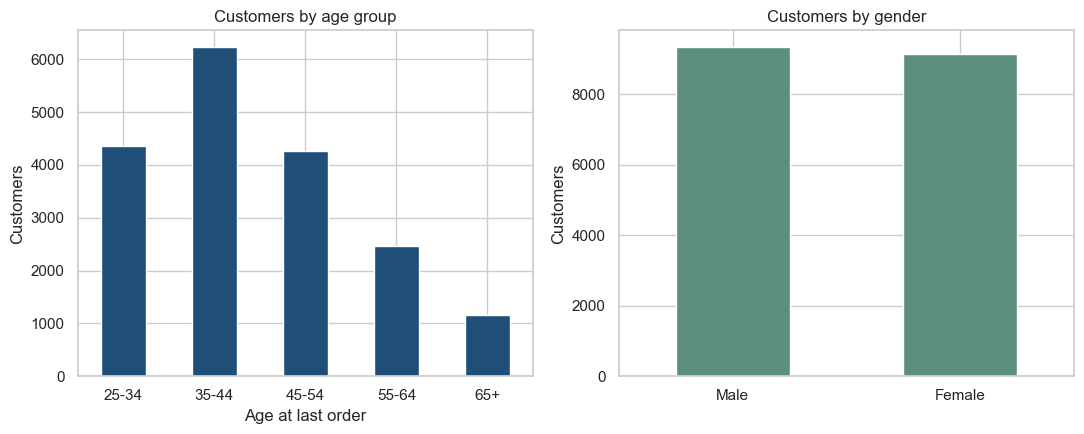

,customers
age_group,
25-34,4357
35-44,6237
45-54,4256
55-64,2457
65+,1158


In [7]:
last_order = sales.dropna(subset=["order_date"]).groupby("customer_key")["order_date"].max()
buyers = customers.merge(last_order.rename("last_order"), on="customer_key", how="inner")
buyers["age"] = ((buyers["last_order"] - buyers["birthdate"]).dt.days / 365.25).round(0)
buyers["age_group"] = pd.cut(buyers["age"], bins=AGE_BINS, labels=AGE_LABELS)

print("customers with a dated order", len(buyers))
age_counts = buyers["age_group"].value_counts().reindex(AGE_LABELS).fillna(0).astype(int)
age_counts = age_counts.loc[age_counts > 0]
gender_counts = buyers["gender"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
age_counts.plot.bar(ax=axes[0], color="#1f4e79", rot=0)
axes[0].set_title("Customers by age group")
axes[0].set_xlabel("Age at last order")
axes[0].set_ylabel("Customers")
gender_counts.plot.bar(ax=axes[1], color="#5b8e7d", rot=0)
axes[1].set_title("Customers by gender")
axes[1].set_xlabel("")
axes[1].set_ylabel("Customers")
fig.tight_layout()
plt.show()

age_counts.to_frame("customers")


There are no buyers under 25. The largest group is 35–44, with 6,237 customers, followed by 25–34 (4,357) and 45–54 (4,256). The count then falls to 2,457 at ages 55–64 and 1,158 at 65 and over. Seventeen buyers have no birth date and are not in the age chart.

Gender is close to even: 9,340 men and 9,127 women, with 15 people unmarked. On the order lines, women account for 14.80 million of sales and men for 14.52 million. Gender is not where this catalogue is won or lost. Age is a stronger split, because spend is concentrated before 55 and thins out after that.


## 6. Products and categories


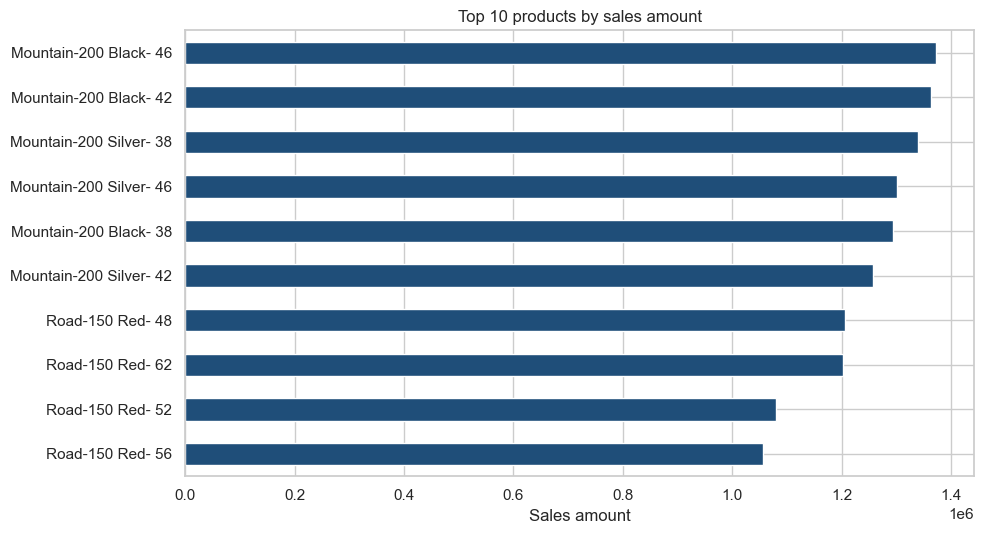

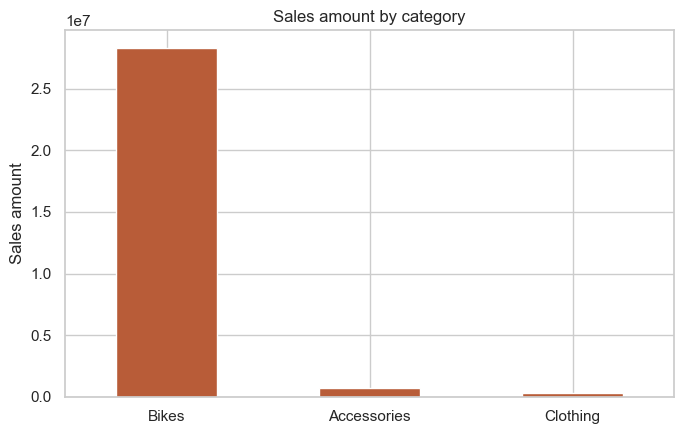

,sales_amount
category,
Bikes,28316272
Accessories,700262
Clothing,339716


In [8]:
top_products = analysis.groupby("product_name")["sales_amount"].sum().nlargest(10).sort_values()
category_revenue = analysis.groupby("category")["sales_amount"].sum().sort_values(ascending=False)
top_units = analysis.groupby("product_name")["quantity"].sum().nlargest(10)

fig, ax = plt.subplots(figsize=(10, 5.5))
top_products.plot.barh(ax=ax, color="#1f4e79")
ax.set_title("Top 10 products by sales amount")
ax.set_xlabel("Sales amount")
ax.set_ylabel("")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
category_revenue.plot.bar(ax=ax, color="#b85c38", rot=0)
ax.set_title("Sales amount by category")
ax.set_xlabel("")
ax.set_ylabel("Sales amount")
fig.tight_layout()
plt.show()

category_revenue.to_frame("sales_amount")


In [9]:
top_units.to_frame("units")


,units
product_name,
Water Bottle - 30 oz.,4249
Patch Kit/8 Patches,3191
Mountain Tire Tube,3096
Road Tire Tube,2376
Sport-100 Helmet- Red,2230
AWC Logo Cap,2190
Sport-100 Helmet- Blue,2126
Fender Set - Mountain,2121
Sport-100 Helmet- Black,2085


Bikes bring in 28.32 million of the 29.36 million total, which is 96.5% of sales. Accessories contribute 0.70 million and clothing 0.34 million.

The ten largest products are all sizes of two bikes: the Mountain-200 and the Road-150. The Mountain-200 Black in size 46 alone is 1.37 million. A stockout on these sizes costs more than a stockout on the rest of the catalogue.

Unit sales point the other way. The quantity leaders are a 30 oz water bottle (4,249 units), a patch kit, tyre tubes, helmets, and a logo cap. Counting units makes the company look like an accessories shop. Counting money makes it a bike shop. The two lists do not overlap.


## 7. Correlation


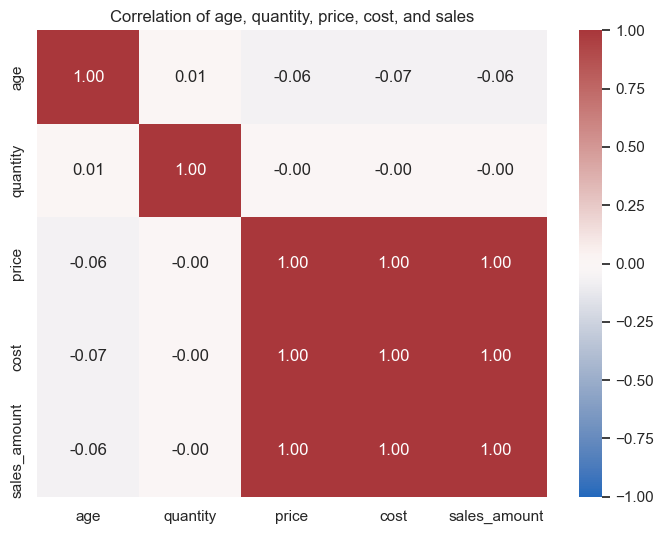

In [10]:
corr = analysis[["age", "quantity", "price", "cost", "sales_amount"]].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of age, quantity, price, cost, and sales")
fig.tight_layout()
plt.show()


Price and sales amount correlate at 1.00. That is not a discovery about customer behaviour. It follows from the data: sales amount equals price times quantity, and quantity is 1 on almost every line. Product cost correlates with price at 1.00 as well (0.997), so cost and price are two readings of the same expensive-bike effect.

Quantity has nothing to correlate with, because it barely moves. Age has a weak negative link with price (−0.06) and with cost (−0.07). Older customers buy slightly cheaper lines, but age does not determine the value of an order. Category and country, in the charts above and below, separate customers more clearly than any of these correlations.


## 8. Revenue per customer by country

The United States has the most customers, so it would be easy to treat it as the most valuable market. This chart divides each country's sales by its number of buying customers.


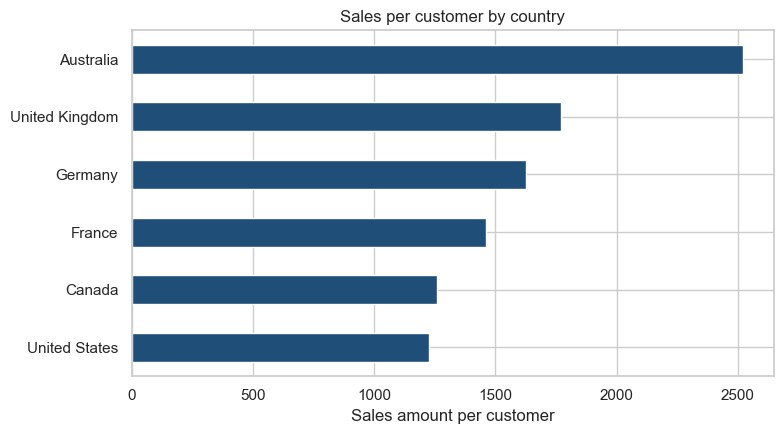

,revenue,customers,revenue_per_customer
country,,,
Australia,9060172,3591,2523.0
United Kingdom,3391376,1913,1773.0
Germany,2894066,1780,1626.0
France,2643751,1810,1461.0
Canada,1977738,1571,1259.0
United States,9162327,7482,1225.0


In [11]:
per_customer = (
    analysis.dropna(subset=["country"])
    .groupby("country")
    .agg(revenue=("sales_amount", "sum"), customers=("customer_key", "nunique"))
)
per_customer["revenue_per_customer"] = per_customer["revenue"] / per_customer["customers"]
per_customer = per_customer.sort_values("revenue_per_customer")

fig, ax = plt.subplots(figsize=(8, 4.5))
per_customer["revenue_per_customer"].plot.barh(ax=ax, color="#1f4e79")
ax.set_title("Sales per customer by country")
ax.set_xlabel("Sales amount per customer")
ax.set_ylabel("")
fig.tight_layout()
plt.show()

per_customer.sort_values("revenue_per_customer", ascending=False).round(0)


Australia and the United States produce almost the same total sales, about 9.06 million and 9.16 million. Australia does it with 3,591 customers. The United States needs 7,482.

An Australian customer is worth about 2,523. A US customer is worth about 1,225, the lowest of the six countries. The United Kingdom (1,773), Germany (1,626), France (1,461), and Canada (1,259) sit in between. Acquisition volume in the United States is not the same thing as customer value. Three hundred and thirty-seven customers have no country and are excluded from this chart.


## 9. Recommendations

1. Stock and advertise the bikes that already carry the business. Bikes are 96.5% of sales, and the top ten products are sizes of the Mountain-200 and the Road-150. Water bottles, patch kits, and tubes can stay as checkout add-ons. They should not set the inventory budget.

2. Spend retention money in Australia before buying more US volume. The two countries generate almost equal sales, but an Australian customer spends about twice what a US customer spends. Keeping one Australian buyer is worth about two new US buyers.

3. Build the operating plan around the fourth quarter and around ages 35–44. December 2013 was the peak month and the last quarter of 2013 was the peak quarter, after a weaker 2012. Customers aged 35–44 are the largest group. Spend drops after 55, so that older group needs a cheaper accessory offer rather than another premium-bike campaign.
